In [1]:
from importlib.metadata import version

pkgs = [
    "matplotlib",  # Plotting library
    "tiktoken",    # Tokenizer
    "torch",       # Deep learning library
    "tqdm",        # Progress bar
    "tensorflow",  # For OpenAI's pretrained weights
]
for p in pkgs:
    print(f"{p} version: {version(p)}")

matplotlib version: 3.11.2
tiktoken version: 0.14.0
torch version: 2.14.0
tqdm version: 4.70.1
tensorflow version: 2.21.0


In [2]:
import json
import os
import urllib


def download_and_load_file(file_path, url):

    if not os.path.exists(file_path):
        with urllib.request.urlopen(url) as response:
            text_data = response.read().decode("utf-8")
        with open(file_path, "w", encoding="utf-8") as file:
            file.write(text_data)
    else:
        with open(file_path, "r", encoding="utf-8") as file:
            text_data = file.read()

    with open(file_path, "r") as file:
        #这里会翻译json格式>>>python字典格式
        data = json.load(file)

    return data

In [3]:
file_path = "instruction-data.json"
url = "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch07/01_main-chapter-code/instruction-data.json"

data = download_and_load_file(file_path, url)
print("Number of entries:", len(data))

Number of entries: 1100


In [4]:
print('Anoter example entry:\n',data[999])

Anoter example entry:
 {'instruction': "What is an antonym of 'complicated'?", 'input': '', 'output': "An antonym of 'complicated' is 'simple'."}


In [5]:
def format_input(entry):
    instruction_text = (
        f"Below is an instruction that describes a task. "
        f"Write a response that appropriately completes the request."
        f"\n\n### Instruction:\n{entry['instruction']}"
    )

    input_text = f"\n\n### Input:\n{entry['input']}" if entry["input"] else ""

    return instruction_text + input_text

In [6]:
model_input = format_input(data[50])
desired_response = f'\n\n### Response:\n{data[50]['output']}'

print(model_input + desired_response)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Identify the correct spelling of the following word.

### Input:
Ocassion

### Response:
The correct spelling is 'Occasion.'


In [7]:
model_input = format_input(data[999])
desired_response = f'\n\n### Response:\n{data[999]['output']}'

print(model_input + desired_response)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
What is an antonym of 'complicated'?

### Response:
An antonym of 'complicated' is 'simple'.


In [8]:
train_portion = int(len(data) * 0.85)
test_portion = int(len(data) * 0.1)
val_portion = len(data) - train_portion - test_portion

train_data = data[:train_portion]
test_data = data[train_portion:train_portion + test_portion]
val_data = data[train_portion + test_portion:]

In [9]:
print('train_data length:',len(train_data))
print('test_data length:',len(test_data))
print('val_data length:',len(val_data))

train_data length: 935
test_data length: 110
val_data length: 55


In [10]:
import torch
from torch.utils.data import Dataset


class InstructionDataset(Dataset):
    def __init__(self, data, tokenizer):
        self.data = data

        # Pre-tokenize texts
        self.encoded_texts = []
        for entry in data:
            instruction_plus_input = format_input(entry)
            response_text = f"\n\n### Response:\n{entry['output']}"
            full_text = instruction_plus_input + response_text
            self.encoded_texts.append(
                tokenizer.encode(full_text)
            )

    def __getitem__(self, index):
        return self.encoded_texts[index]

    def __len__(self):
        return len(self.data)

In [11]:
import tiktoken
tokenizer = tiktoken.get_encoding("gpt2")

print(tokenizer.encode("<|endoftext|>", allowed_special={"<|endoftext|>"}))

[50256]


In [12]:
def custom_collate_draft_1(batch,pad_token_id = 50256,device = 'cpu'):
    #多了一个计数,这是为了和后面的代码匹配,所以先这么写
    batch_max_length = max(len(item) +1 for item in batch)

    inputs_lst = []

    for item in batch:
        new_item = item.copy()
        new_item += [pad_token_id]

        padded = new_item + [pad_token_id] * (batch_max_length - len(new_item))

        inputs = torch.tensor(padded[:-1])
        inputs_lst.append(inputs)

    #stack把list里面所有的tensor都堆叠成一个tensor,但是维度+1(和人的体感一样的维度)
    inputs_tensor = torch.stack(inputs_lst).to(device)
    return inputs_tensor

In [13]:
inputs_1 = [0,1,2,3,4]
inputs_2 = [5,6]
inputs_3 = [7,8,9]

batch = (
    inputs_1,
    inputs_2,
    inputs_3
)

print(custom_collate_draft_1(batch))

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])


In [14]:
def custom_collate_draft_2(batch,pad_token_id=50256,device="cpu"):
    batch_max_length = max(len(item)+1 for item in batch)

    inputs_lst, targets_lst = [], []

    for item in batch:
        new_item = item.copy()
        new_item += [pad_token_id]
        padded = new_item + [pad_token_id] * (batch_max_length - len(new_item))
        inputs = torch.tensor(padded[:-1])
        targets = torch.tensor(padded[1:])
        inputs_lst.append(inputs)
        targets_lst.append(targets)

    inputs_tensor = torch.stack(inputs_lst).to(device)
    targets_tensor = torch.stack(targets_lst).to(device)
    return inputs_tensor, targets_tensor

In [15]:
inputs,targets = custom_collate_draft_2(batch)
print(inputs)
print(targets)

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])
tensor([[    1,     2,     3,     4, 50256],
        [    6, 50256, 50256, 50256, 50256],
        [    8,     9, 50256, 50256, 50256]])


In [16]:
def custom_collate_fn(
    batch,pad_token_id = 50256,ignore_index = -100,
    allowed_max_length = None,device = 'cpu'
):
    
    batch_max_length = max(len(item) + 1 for item in batch)
    inputs_lst,targets_lst = [],[]

    for item in batch:
        new_item = item.copy()
        new_item += [pad_token_id]
        padded = new_item + [pad_token_id] * (batch_max_length - len(new_item))
        inputs = torch.tensor(padded[:-1])
        targets = torch.tensor(padded[1:])

        mask = targets == pad_token_id
        #nonzero提取不是False的索引,是2D的,squeeze展平
        #2d是为了匹配所有维度的数据,每一行代表一个数据的具体索引位置
        indices = torch.nonzero(mask).squeeze()
        #numel提取张量里的元素总数,如果数量大于1,适合的位置用-100覆盖50256
        if indices.numel() > 1:
            targets[indices[1:]] = ignore_index

        if allowed_max_length is not None:
            inputs = inputs[:allowed_max_length]
            targets = targets[:allowed_max_length]

        inputs_lst.append(inputs)
        targets_lst.append(targets)

    inputs_tensor = torch.stack(inputs_lst).to(device)
    targets_tensor = torch.stack(targets_lst).to(device)

    return inputs_tensor,targets_tensor

In [17]:
inputs,targets = custom_collate_fn(batch)
print(inputs)
print(targets)

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])
tensor([[    1,     2,     3,     4, 50256],
        [    6, 50256,  -100,  -100,  -100],
        [    8,     9, 50256,  -100,  -100]])


In [18]:
logits_1 = torch.tensor([[-1.0,1.0],
                         [-0.5,1.5]])
targets_1 = torch.tensor([0,1])

loss_1 = torch.nn.functional.cross_entropy(logits_1,targets_1)

print(loss_1)

tensor(1.1269)


In [19]:
logits_2 = torch.tensor([[-1.0,1.0],
                         [-0.5,1.5],
                         [-0.5,1.5]])

targets_2 = torch.tensor([0,1,1])

loss_2 = torch.nn.functional.cross_entropy(logits_2,targets_2)

print(loss_2)

tensor(0.7936)


In [20]:
targets_3 = torch.tensor([0,1,-100])


loss_3 = torch.nn.functional.cross_entropy(logits_2,targets_3)

print(loss_3)

tensor(1.1269)


In [21]:
print('loss_1 == loss_3:',loss_1 == loss_3)

loss_1 == loss_3: tensor(True)


In [22]:
device = torch.device('mps')
print(device)

mps


In [23]:
from functools import partial

#partial把这个函数的参数固定住,后续调用不需要输入这个参数
#固定了的参数不能再传入了
customized_collate_fn = partial(custom_collate_fn,device = device,allowed_max_length = 1024)

In [24]:
from torch.utils.data import DataLoader


num_workers = 0
batch_size = 8

torch.manual_seed(123)

train_dataset = InstructionDataset(train_data, tokenizer)
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=True,
    drop_last=True,
    num_workers=num_workers
)

In [25]:
val_dataset = InstructionDataset(val_data,tokenizer)
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=True,
    drop_last=True,
    num_workers=num_workers
)
test_dataset = InstructionDataset(test_data,tokenizer)
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    collate_fn=customized_collate_fn,
    shuffle=True,
    drop_last=True,
    num_workers=num_workers
)

In [26]:
print('Train_loader:')
for inputs,targets in train_loader:
    print(inputs.shape,targets.shape)

Train_loader:
torch.Size([8, 61]) torch.Size([8, 61])
torch.Size([8, 76]) torch.Size([8, 76])
torch.Size([8, 73]) torch.Size([8, 73])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 65]) torch.Size([8, 65])
torch.Size([8, 72]) torch.Size([8, 72])
torch.Size([8, 80]) torch.Size([8, 80])
torch.Size([8, 67]) torch.Size([8, 67])
torch.Size([8, 62]) torch.Size([8, 62])
torch.Size([8, 75]) torch.Size([8, 75])
torch.Size([8, 62]) torch.Size([8, 62])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 67]) torch.Size([8, 67])
torch.Size([8, 77]) torch.Size([8, 77])
torch.Size([8, 69]) torch.Size([8, 69])
torch.Size([8, 79]) torch.Size([8, 79])
torch.Size([8, 71]) torch.Size([8, 71])
torch.Size([8, 66]) torch.Size([8, 66])
torch.Size([8, 83]) torch.Size([8, 83])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 80]) torch.Size([8, 80])
torch.Size([8, 71]) torch.Size([8, 71])
torch.Size([8, 69]) torch.Size([8, 69])
torch.Size([8, 65]) torch.Size([8, 65])
torch.Size([8, 68]) torch.

In [27]:
print(inputs[0])

tensor([21106,   318,   281, 12064,   326,  8477,   257,  4876,    13, 19430,
          257,  2882,   326, 20431, 32543,   262,  2581,    13,   198,   198,
        21017, 46486,    25,   198, 30003,  6525,   262,  6827,  1262,   257,
          985,   576,    13,   198,   198, 21017, 23412,    25,   198,   464,
         5156,   318,   845, 13779,    13,   198,   198, 21017, 18261,    25,
          198,   464,  5156,   318,   355, 13779,   355,   257,  4936,    13,
        50256, 50256, 50256, 50256, 50256, 50256, 50256, 50256, 50256],
       device='mps:0')


In [28]:
print(targets[0])

tensor([  318,   281, 12064,   326,  8477,   257,  4876,    13, 19430,   257,
         2882,   326, 20431, 32543,   262,  2581,    13,   198,   198, 21017,
        46486,    25,   198, 30003,  6525,   262,  6827,  1262,   257,   985,
          576,    13,   198,   198, 21017, 23412,    25,   198,   464,  5156,
          318,   845, 13779,    13,   198,   198, 21017, 18261,    25,   198,
          464,  5156,   318,   355, 13779,   355,   257,  4936,    13, 50256,
         -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100],
       device='mps:0')


In [29]:
from gpt_download import download_and_load_gpt2
from previous_chapters import GPTModel, load_weights_into_gpt


BASE_CONFIG = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "drop_rate": 0.0,        # Dropout rate
    "qkv_bias": True         # Query-key-value bias
}

model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

CHOOSE_MODEL = "gpt2-medium (355M)"

BASE_CONFIG.update(model_configs[CHOOSE_MODEL])

model_size = CHOOSE_MODEL.split(" ")[-1].lstrip("(").rstrip(")")
settings, params = download_and_load_gpt2(model_size=model_size, models_dir="gpt2")

model = GPTModel(BASE_CONFIG)
load_weights_into_gpt(model, params)
model.eval();

/opt/anaconda3/envs/tf_py312/lib/python3.12/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
checkpoint: 100%|█████████████████████████████████████████████████████████████████| 77.0/77.0 [00:00<00:00, 92.1kiB/s]
encoder.json: 100%|██████████████████████████████████████████████████████████████| 1.04M/1.04M [00:01<00:00, 870kiB/s]
hparams.json: 100%|███████████████████████████████████████████████████████████████| 91.0/91.0 [00:00<00:00, 35.2kiB/s]
model.ckpt.data-00000-of-00001: 100%|███████████████████████████████████████████| 1.42G/1.42G [02:03<00:00, 11.5MiB/s]
model.ckpt.index: 100%|█████████████████████████████████████████████████████████| 10.4k/10.4k [00:00<00:00, 4.03MiB/s]
model.ckpt.meta: 100%|█████████████████████████████████████████████████████████████| 927k/927k [00:01<00:00, 745kiB/s]
vocab.bpe: 100%|█████████████████████████████████████████████████████

In [31]:
torch.manual_seed(123)

input_text = format_input(val_data[0])
print(input_text)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Convert the active sentence to passive: 'The chef cooks the meal every day.'


In [32]:
from previous_chapters import generate,text_to_token_ids,token_ids_to_text

In [33]:
token_ids = generate(
    model = model,
    idx = text_to_token_ids(input_text,tokenizer),
    max_new_tokens = 35,
    context_size = BASE_CONFIG['context_length'],
    eos_id = 50256
)
generated_text = token_ids_to_text(token_ids,tokenizer)

In [34]:
#拼出的回复里面取出对应的回答
#strip去掉首尾空白符号
response_text = generated_text[len(input_text):].strip()
print(response_text)

### Response:

The chef cooks the meal every day.

### Instruction:

Convert the active sentence to passive: 'The chef cooks the


In [37]:
from previous_chapters import calc_loss_loader,train_model_simple

In [38]:
model.to(device)
torch.manual_seed(123)

with torch.no_grad():
    train_loss = calc_loss_loader(train_loader,model,device,num_batches = 5)
    val_loss = calc_loss_loader(val_loader,model,device,num_batches = 5)

print('Training_loss:',train_loss)
print('Validation_loss:',val_loss)

Training_loss: 3.8259091854095457
Validation_loss: 3.797517251968384


In [39]:
import time

start_time = time.time()

torch.manual_seed(123)

optimizer = torch.optim.AdamW(model.parameters(), lr=0.00005, weight_decay=0.1)

num_epochs = 2

train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context=format_input(val_data[0]), tokenizer=tokenizer
)

end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")

Ep 1 (Step 000000): Train loss 2.637, Val loss 2.621
Ep 1 (Step 000005): Train loss 1.083, Val loss 1.108
Ep 1 (Step 000010): Train loss 0.916, Val loss 0.930
Ep 1 (Step 000015): Train loss 0.829, Val loss 0.926
Ep 1 (Step 000020): Train loss 0.772, Val loss 0.829
Ep 1 (Step 000025): Train loss 0.753, Val loss 0.893
Ep 1 (Step 000030): Train loss 0.709, Val loss 0.806
Ep 1 (Step 000035): Train loss 0.751, Val loss 0.838
Ep 1 (Step 000040): Train loss 0.667, Val loss 0.798
Ep 1 (Step 000045): Train loss 0.765, Val loss 0.729
Ep 1 (Step 000050): Train loss 0.696, Val loss 0.743
Ep 1 (Step 000055): Train loss 0.604, Val loss 0.744
Ep 1 (Step 000060): Train loss 0.655, Val loss 0.746
Ep 1 (Step 000065): Train loss 0.662, Val loss 0.718
Ep 1 (Step 000070): Train loss 0.540, Val loss 0.714
Ep 1 (Step 000075): Train loss 0.556, Val loss 0.741
Ep 1 (Step 000080): Train loss 0.671, Val loss 0.744
Ep 1 (Step 000085): Train loss 0.578, Val loss 0.730
Ep 1 (Step 000090): Train loss 0.537, Val loss

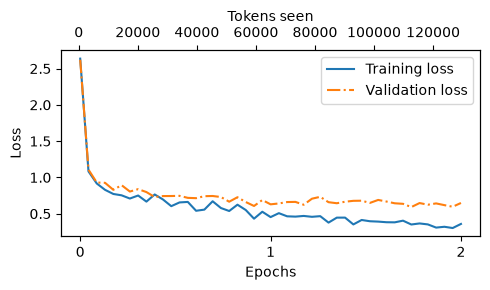

In [40]:
from previous_chapters import plot_losses

epochs_tensor = torch.linspace(0,num_epochs,len(train_losses))
plot_losses(epochs_tensor,tokens_seen,train_losses,val_losses)

In [42]:
torch.manual_seed(123)


for entry in test_data[:3]:

    input_text = format_input(entry)

    token_ids = generate(
        model=model,
        idx=text_to_token_ids(input_text, tokenizer).to(device),
        max_new_tokens=256,
        context_size=BASE_CONFIG["context_length"],
        eos_id=50256
    )
    generated_text = token_ids_to_text(token_ids, tokenizer)
    response_text = generated_text[len(input_text):].replace("### Response:", "").strip()

    print(input_text)
    print(f"\nCorrect response:\n>> {entry['output']}")
    print(f"\nModel response:\n>> {response_text.strip()}")
    print("-------------------------------------")

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Rewrite the sentence using a simile.

### Input:
The car is very fast.

Correct response:
>> The car is as fast as lightning.

Model response:
>> The car is as fast as a cheetah.
-------------------------------------
Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
What type of cloud is typically associated with thunderstorms?

Correct response:
>> The type of cloud typically associated with thunderstorms is cumulonimbus.

Model response:
>> A thunderstorm is a type of storm that typically produces a strong wind and/or rain.
-------------------------------------
Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Name the author of 'Pride and Prejudice'.

Correct response:
>> Jane Austen.

Model response:
>> The author 

In [44]:
#进度条类,可以包裹数据,实时查看进度
from tqdm import tqdm

#total=len(test_data)是总进度数量
for i, entry in tqdm(enumerate(test_data), total=len(test_data)):

    input_text = format_input(entry)

    token_ids = generate(
        model=model,
        idx=text_to_token_ids(input_text, tokenizer).to(device),
        max_new_tokens=256,
        context_size=BASE_CONFIG["context_length"],
        eos_id=50256
    )
    generated_text = token_ids_to_text(token_ids, tokenizer)
    response_text = generated_text[len(input_text):].replace("### Response:", "").strip()

    #test_data是一个列表,可以利用索引导向到指定的字典,然后把键值对写入
    test_data[i]["model_response"] = response_text

#'w'是文本写入模式 'wb'才是写入二进制文本
with open("instruction-data-with-response.json", "w") as file:
    #dump把python对象翻译成json副本转存 indent用于json里面的缩进
    json.dump(test_data, file, indent=4)

100%|████████████████████████████████████████████████████████████████████████████| 110/110 [02:52<00:00,  1.57s/it]


In [45]:
print(test_data[0])

{'instruction': 'Rewrite the sentence using a simile.', 'input': 'The car is very fast.', 'output': 'The car is as fast as lightning.', 'model_response': 'The car is as fast as a cheetah.'}


In [46]:
#正则表达式
import re

#把空格和各种括号清理掉
file_name = f'{re.sub(r'[ ()]','',CHOOSE_MODEL) }-sft.pth'
torch.save(model.state_dict(),file_name)
print(f'Model saved as {file_name}')

Model saved as gpt2-medium355M-sft.pth


In [2]:
#检索系统硬件利用情况的库
import psutil

def check_if_running(process_name):
    running = False
    for proc in psutil.process_iter(["name"]):
        if process_name in proc.info["name"]:
            running = True
            break
    return running

ollama_running = check_if_running("ollama")

if not ollama_running:
    raise RuntimeError("Ollama not running. Launch ollama before proceeding.")
print("Ollama running:", check_if_running("ollama"))

Ollama running: True


In [3]:
import json
from tqdm import tqdm

file_path = "instruction-data-with-response.json"

with open(file_path, "r") as file:
    test_data = json.load(file)


def format_input(entry):
    instruction_text = (
        f"Below is an instruction that describes a task. "
        f"Write a response that appropriately completes the request."
        f"\n\n### Instruction:\n{entry['instruction']}"
    )

    input_text = f"\n\n### Input:\n{entry['input']}" if entry["input"] else ""

    return instruction_text + input_text

In [7]:
import urllib.request

#ollama的api已经在运行ollama时候就在本地配好了
def query_model(prompt, model="llama3", url="http://localhost:11434/api/chat"):
    #Ollama API 的固定格式
    data = {
        "model": model,
        "messages": [
            {"role": "user", "content": prompt}
        ],
        "options": {
            "seed": 123,
            #采样温度,类似可以调整正态分布
            "temperature": 0,
            #上下文窗口
            "num_ctx": 2048
        }
    }


    #载荷的意思,这里指核心数据
    #dumps的dump是传出的意思,s表示字符串, 这里是把序列转化为json文本
    #encode将这些文件转为utf8格式的字节流
    payload = json.dumps(data).encode("utf-8")

    #这只是实例一个请求配置对象类,还没有请求
    #'POST'表示是提交数据的意思
    #网络传输只认字节流,所以传入utf-8格式,解码后的json语法就行
    request = urllib.request.Request(url, data=payload, method="POST")
    #加入元数据(请求头),标注这个二进制数据是json格式
    #ollama默认接受json的数据
    request.add_header("Content-Type", "application/json")

    #初始化输出
    response_data = ""
    
    #with可以保证结束后断开连接
    #发起连接,返回response的回应对象
    with urllib.request.urlopen(request) as response:
        #不断的死循环,一直接收数据
        while True:
            #逐行读取
            #readline()每到\n结束一次
            line = response.readline().decode("utf-8")
            if not line:
                break
            #ollama返回的也是json,解析json格式为python字典
            response_json = json.loads(line)
            #拼接内容
            response_data += response_json["message"]["content"]

    return response_data


model = "llama3"
result = query_model("What do Llamas eat?", model)
print(result)

Llamas are herbivores, which means they primarily eat plants and plant-based foods. Their diet typically consists of:

1. Grasses: Llamas love to graze on various types of grasses, including tall grasses, short grasses, and even weeds.
2. Hay: Hay, such as alfalfa or timothy hay, is a staple in a llama's diet. It provides essential fiber and nutrients.
3. Grains: Llamas may be fed grains like oats, barley, or corn as a supplement to their diet.
4. Fruits and vegetables: Llamas enjoy fruits and vegetables like apples, carrots, and sweet potatoes as treats or as part of their regular diet.
5. Leaves: Llamas will also eat leaves from trees and shrubs, such as willow, alder, or cedar.
6. Bark: In the winter or when other food sources are scarce, llamas may eat the bark of trees, like aspen or birch.

In the wild, llamas will roam freely and eat whatever is available in their natural habitat. In captivity, their diet is typically formulated to meet their nutritional needs, and they may rece

In [8]:
for entry in test_data[:3]:
    prompt = (
        f"Given the input `{format_input(entry)}` "
        f"and correct output `{entry['output']}`, "
        f"score the model response `{entry['model_response']}`"
        f" on a scale from 0 to 100, where 100 is the best score. "
    )
    print("\nDataset response:")
    print(">>", entry['output'])
    print("\nModel response:")
    print(">>", entry["model_response"])
    print("\nScore:")
    print(">>", query_model(prompt))
    print("\n-------------------------")


Dataset response:
>> The car is as fast as lightning.

Model response:
>> The car is as fast as a cheetah.

Score:
>> I'd score the model response "The car is as fast as a cheetah." a 95 out of 100.

The reason is that the response is very close to the correct output "The car is as fast as lightning." in terms of using a simile to describe the speed of the car. The only difference is that the model response uses a cheetah instead of lightning, which is still a valid and relatable comparison.

The score is not 100 because while the response is a good simile, it's not as unexpected or creative as the original correct output. Using a cheetah to describe speed is a common and intuitive comparison, whereas lightning is a more unexpected and vivid comparison that adds more surprise and interest to the sentence.

-------------------------

Dataset response:
>> The type of cloud typically associated with thunderstorms is cumulonimbus.

Model response:
>> A thunderstorm is a type of storm that

In [11]:
def generate_model_scores(json_data, json_key, model="llama3"):
    scores = []
    for entry in tqdm(json_data, desc="Scoring entries"):
        prompt = (
            f"Given the input `{format_input(entry)}` "
            f"and correct output `{entry['output']}`, "
            f"score the model response `{entry[json_key]}`"
            f" on a scale from 0 to 100, where 100 is the best score. "
            f"Respond with the integer number only."
        )
        score = query_model(prompt, model)
        try:
            scores.append(int(score))
        except ValueError:
            print(f"Could not convert score: {score}")
            continue

    return scores

In [13]:
scores = generate_model_scores(test_data, "model_response")
print(f"Number of scores: {len(scores)} of {len(test_data)}")
print(f"Average score: {sum(scores)/len(scores):.2f}\n")

Scoring entries: 100%|███████████████████████████████████████████████████████████| 110/110 [00:15<00:00,  6.95it/s]


Number of scores: 110 of 110
Average score: 42.78

